# Kiểm chứng công thức điểm ưu tiên S

**Công thức đề xuất:**  S = AC × CVSS × [KEV + (1 - KEV) × EPSS^0,3] × 10

- AC: hệ số quan trọng của tài sản, trong khoảng 0 đến 1.
- CVSS: điểm mức độ nghiêm trọng, thang 0 đến 10.
- KEV: bằng 1 nếu lỗ hổng đã có trong KEV tại thời điểm đánh giá, ngược lại bằng 0.
- EPSS: xác suất bị khai thác trong 30 ngày tới, từ 0 đến 1.
- S: điểm ưu tiên, thang 0 đến 100 (CVSS dùng thang 0 đến 10 rồi nhân 10; nếu CVSS đã chuẩn hóa về 0 đến 1 thì nhân 100).

**Cách kiểm chứng (tạm bỏ AC, tức AC = 1):**

1. Chọn một ngày đánh giá T trong quá khứ. Chỉ dùng thông tin có tại ngày T: điểm EPSS ngày T và danh mục KEV tính đến ngày T.
2. Lỗ hổng đã có trong KEV tại T có S = CVSS × 10. Phần này đã bị khai thác nên không cần chứng minh.
3. Lỗ hổng chưa có trong KEV tại T có S = CVSS × EPSS^0,3 × 10. **Đây là phần cần chứng minh:** điểm S có dự đoán được lỗ hổng nào sẽ vào KEV trong 12 tháng sau ngày T hay không.
4. Chia S thành 10 mức, mỗi mức 10 điểm. Đếm số lỗ hổng trong mỗi mức và số lỗ hổng thực sự vào KEV trong 12 tháng sau.
5. So sánh với quy tắc của CSA (vá mọi lỗ hổng CVSS từ 8,0) khi cùng khối lượng vá.

Ba ngày đánh giá: 31/12/2023, 31/12/2024 và 30/06/2025. Ngày 30/06/2025 là kết quả chính vì dùng mô hình EPSS mới nhất có đủ 12 tháng theo dõi.

**Cách chạy trên Google Colab:** tải notebook lên Colab, chọn *Runtime, Run all*. Kết quả được lưu trong thư mục `ket_qua_S`.

## 1. Cấu hình và hàm dùng chung

In [1]:
import os, io, json, gzip, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

START_YEAR, END_YEAR = 2002, 2025
NGAY_DANH_GIA = ["2023-12-31", "2024-12-31", "2025-06-30"]
NGAY_CHINH = "2025-06-30"
THEO_DOI = 365                     # so ngay theo doi sau ngay danh gia
SO_MU = 0.3
NGUONG_CSA = 8.0
DATA_DIR, OUT_DIR = "du_lieu_nvd", "ket_qua_S"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

NVD_FEED = "https://nvd.nist.gov/feeds/json/cve/2.0/nvdcve-2.0-{y}.json.gz"
KEV_URL = "https://raw.githubusercontent.com/cisagov/kev-data/develop/known_exploited_vulnerabilities.json"
EPSS_URL = "https://epss.empiricalsecurity.com/epss_scores-{d}.csv.gz"
UA = {"User-Agent": "Nhom14-course-research"}
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})

def tai(url, path):
    if os.path.exists(path):
        return open(path, "rb").read()
    data = urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=300).read()
    open(path, "wb").write(data)
    return data

def so(x): return f"{int(round(x)):,}".replace(",", ".")
def pct(v, k=2): return f"{v:.{k}f}".replace(".", ",")
def ty_le(a, b, k=None):
    """Ghi ro tu so va mau so. So rat nho thi lay 3 chu so thap phan."""
    if b == 0: return ""
    p = 100 * a / b
    if k is None: k = 3 if 0 < p < 0.1 else 2
    a_txt = so(a) if float(a).is_integer() else pct(a, 1)
    return f"{a_txt} / {so(b)} = {pct(p, k)}%"

def diem_S(cvss, epss, kev, ac=1.0):
    return ac * cvss * (kev + (1 - kev) * np.power(epss, SO_MU)) * 10

def so_bat_duoc(diem, y, k):
    """So lo hong vao KEV nam trong k lo hong diem cao nhat.
    Neu nhieu lo hong bang diem o ranh gioi thi lay gia tri ky vong (chon ngau nhien trong nhom bang diem)."""
    g = pd.DataFrame({"d": diem, "y": y}).groupby("d")["y"].agg(["size", "sum"]).sort_index(ascending=False)
    lay, con = 0.0, k
    for n, s in zip(g["size"], g["sum"]):
        if con <= 0: break
        t = min(n, con); lay += s * t / n; con -= t
    return lay

BANG, SO_LIEU = {}, {}

## 2. Tải danh mục KEV và điểm CVSS kèm ngày công bố

In [2]:
kev = pd.DataFrame(json.loads(tai(KEV_URL, os.path.join(DATA_DIR, "kev.json")))["vulnerabilities"])
kev["cveID"] = kev["cveID"].str.upper(); kev["ngay_kev"] = pd.to_datetime(kev["dateAdded"])
print(f"KEV: {so(len(kev))} lỗ hổng")

def chon(ds):
    if not ds: return None
    for m in ds:
        if m.get("type") == "Primary": return m
    return ds[0]

rows = []
for y in range(START_YEAR, END_YEAR + 1):
    js = json.loads(gzip.decompress(tai(NVD_FEED.format(y=y), os.path.join(DATA_DIR, f"nvdcve-2.0-{y}.json.gz"))))
    for it in js["vulnerabilities"]:
        c = it["cve"]
        if c.get("vulnStatus") == "Rejected": continue
        met = c.get("metrics", {})
        v3 = chon(met.get("cvssMetricV31")) or chon(met.get("cvssMetricV30"))
        rows.append({"cve": c["id"].upper(), "ngay_cong_bo": c["published"][:10],
                     "cvss": v3["cvssData"]["baseScore"] if v3 else np.nan})
nvd = pd.DataFrame(rows).drop_duplicates("cve")
nvd["ngay_cong_bo"] = pd.to_datetime(nvd["ngay_cong_bo"])
nvd["ngay_kev"] = nvd["cve"].map(dict(zip(kev["cveID"], kev["ngay_kev"])))
print(f"NVD: {so(len(nvd))} lỗ hổng, {so(nvd['cvss'].notna().sum())} có CVSS 3.x")

KEV: 1.739 lỗ hổng


NVD: 316.367 lỗ hổng, 240.409 có CVSS 3.x


## 3. Dựng dữ liệu tại từng ngày đánh giá

Tại ngày T: lấy mọi lỗ hổng đã công bố và có CVSS 3.x. Chia làm hai phần: đã có trong KEV tại T, và chưa có trong KEV tại T. Với phần chưa có trong KEV, nhãn kết quả là có vào KEV trong 365 ngày sau T hay không. Lỗ hổng không có điểm EPSS tại T được coi EPSS = 0.

In [3]:
DL = {}
b1 = []
for T in NGAY_DANH_GIA:
    Tt = pd.Timestamp(T); H = Tt + pd.Timedelta(days=THEO_DOI)
    raw = gzip.decompress(tai(EPSS_URL.format(d=T), os.path.join(DATA_DIR, f"epss_{T}.csv.gz"))).decode()
    ep = pd.read_csv(io.StringIO(raw), comment="#")
    x = nvd[(nvd["ngay_cong_bo"] <= Tt) & nvd["cvss"].notna()].copy()
    da_kev = x["ngay_kev"].notna() & (x["ngay_kev"] <= Tt)
    x["kev"] = da_kev.astype(int)
    x["epss"] = x["cve"].map(dict(zip(ep["cve"].str.upper(), ep["epss"])))
    thieu = int(x.loc[~da_kev, "epss"].isna().sum()); x["epss"] = x["epss"].fillna(0.0)
    x["S"] = diem_S(x["cvss"].values, x["epss"].values, x["kev"].values)
    x["y"] = (x["ngay_kev"].notna() & (x["ngay_kev"] > Tt) & (x["ngay_kev"] <= H)).astype(int)
    DL[T] = x
    moi = kev[(kev["ngay_kev"] > Tt) & (kev["ngay_kev"] <= H)]
    # Lo hong vao KEV trong 12 thang sau T nhung khong thuoc nhom can du doan: cong bo sau T
    # (ke ca ma CVE nam sau END_YEAR, khong co trong tep NVD da tai) hoac khong co CVSS 3.x
    pub = moi["cveID"].map(nvd.set_index("cve")["ngay_cong_bo"])
    nam_ma = moi["cveID"].str.split("-").str[1].astype(int)
    sau_T = int(((pub > Tt) | (pub.isna() & (nam_ma > END_YEAR))).sum())
    chua = x[x["kev"] == 0]; P = int(chua["y"].sum()); khong_cvss3 = len(moi) - P - sau_T
    b1.append([T, raw.splitlines()[0].split(",")[0].replace("#model_version:", ""), so(len(x)), so(da_kev.sum()), so(len(chua)),
               so(thieu), so(len(moi)), ty_le(P, len(moi)), ty_le(sau_T, len(moi)), ty_le(khong_cvss3, len(moi))])
    SO_LIEU[T] = dict(N=len(x), kev_T=int(da_kev.sum()), chua=len(chua), thieu_epss=thieu, kev_moi=len(moi), P=P,
                      sau_T=sau_T, khong_cvss3=khong_cvss3)
b1 = pd.DataFrame(b1, columns=["Ngày đánh giá", "Mô hình EPSS", "Lỗ hổng đã công bố có CVSS 3.x", "Đã có trong KEV tại ngày đó",
                               "Chưa có trong KEV (cần dự đoán)", "Trong đó không có điểm EPSS", "KEV thêm trong 12 tháng sau",
                               "Trong đó thuộc nhóm cần dự đoán", "Trong đó công bố sau ngày đánh giá",
                               "Trong đó công bố trước nhưng không có CVSS 3.x"])
BANG["B1 Tong quan"] = b1
display(b1.T)

,0,1,2
Ngày đánh giá,2023-12-31,2024-12-31,2025-06-30
Mô hình EPSS,v2023.03.01,v2023.03.01,v2025.03.14
Lỗ hổng đã công bố có CVSS 3.x,148.366,187.995,210.994
Đã có trong KEV tại ngày đó,1.053,1.239,1.371
Chưa có trong KEV (cần dự đoán),147.313,186.756,209.623
Trong đó không có điểm EPSS,29,593,46
KEV thêm trong 12 tháng sau,186,245,259
Trong đó thuộc nhóm cần dự đoán,"61 / 186 = 32,80%","80 / 245 = 32,65%","91 / 259 = 35,14%"
Trong đó công bố sau ngày đánh giá,"125 / 186 = 67,20%","165 / 245 = 67,35%","168 / 259 = 64,86%"
Trong đó công bố trước nhưng không có CVSS 3.x,"0 / 186 = 0,00%","0 / 245 = 0,00%","0 / 259 = 0,00%"


## 4. Bảng 2. Phân bố điểm S theo mức 10 điểm, phần chưa có trong KEV (phần cần chứng minh)

- **Số lỗ hổng trong mức:** so với tổng số lỗ hổng chưa có trong KEV.
- **Vào KEV trong 12 tháng:** tỷ lệ so với số lỗ hổng trong mức, cho biết lỗ hổng ở mức này có khả năng bị khai thác bao nhiêu.
- **So với tổng số vào KEV:** mức này chứa bao nhiêu phần trăm số lỗ hổng sẽ bị khai thác.
- **Gấp bao nhiêu lần trung bình:** tỷ lệ vào KEV của mức chia cho tỷ lệ chung.

In [4]:
MUC = list(range(0, 100, 10))
NHAN = [f"{a} đến dưới {a + 10}" if a < 90 else "90 đến 100" for a in MUC]
def bang_muc(T):
    x = DL[T]; c = x[x["kev"] == 0].copy(); N, P = len(c), int(c["y"].sum()); tb = P / N
    c["muc"] = pd.cut(c["S"], MUC + [100.001], labels=NHAN, right=False)
    t = c.groupby("muc", observed=False)["y"].agg(["size", "sum"])
    out = pd.DataFrame({"Mức điểm S": NHAN,
                        "Số lỗ hổng trong mức": [ty_le(n, N) for n in t["size"]],
                        "Vào KEV trong 12 tháng": [ty_le(k, n) for n, k in zip(t["size"], t["sum"])],
                        "So với tổng số vào KEV": [ty_le(k, P) for k in t["sum"]],
                        "Gấp bao nhiêu lần trung bình": [pct((k / n) / tb, 1) if n else "" for n, k in zip(t["size"], t["sum"])]})
    out.loc[len(out)] = ["Tổng", so(N), ty_le(P, N), so(P), "1,0"]
    SO_LIEU[T]["muc"] = {m: dict(n=int(n), k=int(k)) for m, n, k in zip(NHAN, t["size"], t["sum"])}
    return out
for T in NGAY_DANH_GIA:
    b = bang_muc(T); BANG[f"B2 Muc diem {T}"] = b
    print(f"\nNGÀY ĐÁNH GIÁ {T}"); display(b)


NGÀY ĐÁNH GIÁ 2023-12-31


,Mức điểm S,Số lỗ hổng trong mức,Vào KEV trong 12 tháng,So với tổng số vào KEV,Gấp bao nhiêu lần trung bình
0,0 đến dưới 10,"87.574 / 147.313 = 59,45%","8 / 87.574 = 0,009%","8 / 61 = 13,11%","0,2"
1,10 đến dưới 20,"44.779 / 147.313 = 30,40%","18 / 44.779 = 0,040%","18 / 61 = 29,51%","1,0"
2,20 đến dưới 30,"8.620 / 147.313 = 5,85%","5 / 8.620 = 0,058%","5 / 61 = 8,20%","1,4"
3,30 đến dưới 40,"2.570 / 147.313 = 1,74%","5 / 2.570 = 0,19%","5 / 61 = 8,20%","4,7"
4,40 đến dưới 50,"1.048 / 147.313 = 0,71%","5 / 1.048 = 0,48%","5 / 61 = 8,20%","11,5"
5,50 đến dưới 60,"728 / 147.313 = 0,49%","3 / 728 = 0,41%","3 / 61 = 4,92%","10,0"
6,60 đến dưới 70,"495 / 147.313 = 0,34%","3 / 495 = 0,61%","3 / 61 = 4,92%","14,6"
7,70 đến dưới 80,"638 / 147.313 = 0,43%","3 / 638 = 0,47%","3 / 61 = 4,92%","11,4"
8,80 đến dưới 90,"410 / 147.313 = 0,28%","4 / 410 = 0,98%","4 / 61 = 6,56%","23,6"
9,90 đến 100,"451 / 147.313 = 0,31%","7 / 451 = 1,55%","7 / 61 = 11,48%","37,5"



NGÀY ĐÁNH GIÁ 2024-12-31


,Mức điểm S,Số lỗ hổng trong mức,Vào KEV trong 12 tháng,So với tổng số vào KEV,Gấp bao nhiêu lần trung bình
0,0 đến dưới 10,"115.978 / 186.756 = 62,10%","25 / 115.978 = 0,022%","25 / 80 = 31,25%","0,5"
1,10 đến dưới 20,"52.287 / 186.756 = 28,00%","22 / 52.287 = 0,042%","22 / 80 = 27,50%","1,0"
2,20 đến dưới 30,"10.722 / 186.756 = 5,74%","8 / 10.722 = 0,075%","8 / 80 = 10,00%","1,7"
3,30 đến dưới 40,"3.145 / 186.756 = 1,68%","3 / 3.145 = 0,095%","3 / 80 = 3,75%","2,2"
4,40 đến dưới 50,"1.431 / 186.756 = 0,77%","0 / 1.431 = 0,00%","0 / 80 = 0,00%","0,0"
5,50 đến dưới 60,"914 / 186.756 = 0,49%","4 / 914 = 0,44%","4 / 80 = 5,00%","10,2"
6,60 đến dưới 70,"815 / 186.756 = 0,44%","2 / 815 = 0,25%","2 / 80 = 2,50%","5,7"
7,70 đến dưới 80,"682 / 186.756 = 0,37%","3 / 682 = 0,44%","3 / 80 = 3,75%","10,3"
8,80 đến dưới 90,"386 / 186.756 = 0,21%","7 / 386 = 1,81%","7 / 80 = 8,75%","42,3"
9,90 đến 100,"396 / 186.756 = 0,21%","6 / 396 = 1,52%","6 / 80 = 7,50%","35,4"



NGÀY ĐÁNH GIÁ 2025-06-30


,Mức điểm S,Số lỗ hổng trong mức,Vào KEV trong 12 tháng,So với tổng số vào KEV,Gấp bao nhiêu lần trung bình
0,0 đến dưới 10,"100.819 / 209.623 = 48,10%","11 / 100.819 = 0,011%","11 / 91 = 12,09%","0,3"
1,10 đến dưới 20,"72.627 / 209.623 = 34,65%","20 / 72.627 = 0,028%","20 / 91 = 21,98%","0,6"
2,20 đến dưới 30,"17.999 / 209.623 = 8,59%","3 / 17.999 = 0,017%","3 / 91 = 3,30%","0,4"
3,30 đến dưới 40,"7.541 / 209.623 = 3,60%","7 / 7.541 = 0,093%","7 / 91 = 7,69%","2,1"
4,40 đến dưới 50,"3.769 / 209.623 = 1,80%","4 / 3.769 = 0,11%","4 / 91 = 4,40%","2,4"
5,50 đến dưới 60,"2.348 / 209.623 = 1,12%","5 / 2.348 = 0,21%","5 / 91 = 5,49%","4,9"
6,60 đến dưới 70,"1.717 / 209.623 = 0,82%","7 / 1.717 = 0,41%","7 / 91 = 7,69%","9,4"
7,70 đến dưới 80,"1.206 / 209.623 = 0,58%","14 / 1.206 = 1,16%","14 / 91 = 15,38%","26,7"
8,80 đến dưới 90,"777 / 209.623 = 0,37%","10 / 777 = 1,29%","10 / 91 = 10,99%","29,6"
9,90 đến 100,"820 / 209.623 = 0,39%","10 / 820 = 1,22%","10 / 91 = 10,99%","28,1"


## 5. Bảng 3. Nếu vá mọi lỗ hổng có S từ một mức trở lên

So với quy tắc CSA (vá mọi lỗ hổng CVSS từ 8,0) trên cùng tập lỗ hổng chưa có trong KEV.

In [5]:
def bang_tich_luy(T):
    x = DL[T]; c = x[x["kev"] == 0]; N, P = len(c), int(c["y"].sum())
    rows = []
    for m in range(90, -1, -10):
        sel = c["S"] >= m; n, k = int(sel.sum()), int(c.loc[sel, "y"].sum())
        rows.append([f"S từ {m} trở lên", ty_le(n, N), ty_le(k, P), pct(n / k, 1) if k else ""])
    sel = c["cvss"] >= NGUONG_CSA; n, k = int(sel.sum()), int(c.loc[sel, "y"].sum())
    rows.append(["Quy tắc CSA: CVSS từ 8,0", ty_le(n, N), ty_le(k, P), pct(n / k, 1)])
    SO_LIEU[T]["csa"] = dict(n=n, k=k)
    return pd.DataFrame(rows, columns=["Cách chọn lỗ hổng để vá", "Số lỗ hổng phải vá", "Bắt được lỗ hổng sẽ vào KEV",
                                       "Số lỗ hổng phải vá cho 1 lỗ hổng bắt được"])
for T in NGAY_DANH_GIA:
    b = bang_tich_luy(T); BANG[f"B3 Tich luy {T}"] = b
    print(f"\nNGÀY ĐÁNH GIÁ {T}"); display(b)


NGÀY ĐÁNH GIÁ 2023-12-31


,Cách chọn lỗ hổng để vá,Số lỗ hổng phải vá,Bắt được lỗ hổng sẽ vào KEV,Số lỗ hổng phải vá cho 1 lỗ hổng bắt được
0,S từ 90 trở lên,"451 / 147.313 = 0,31%","7 / 61 = 11,48%","64,4"
1,S từ 80 trở lên,"861 / 147.313 = 0,58%","11 / 61 = 18,03%","78,3"
2,S từ 70 trở lên,"1.499 / 147.313 = 1,02%","14 / 61 = 22,95%","107,1"
3,S từ 60 trở lên,"1.994 / 147.313 = 1,35%","17 / 61 = 27,87%","117,3"
4,S từ 50 trở lên,"2.722 / 147.313 = 1,85%","20 / 61 = 32,79%","136,1"
5,S từ 40 trở lên,"3.770 / 147.313 = 2,56%","25 / 61 = 40,98%","150,8"
6,S từ 30 trở lên,"6.340 / 147.313 = 4,30%","30 / 61 = 49,18%","211,3"
7,S từ 20 trở lên,"14.960 / 147.313 = 10,16%","35 / 61 = 57,38%","427,4"
8,S từ 10 trở lên,"59.739 / 147.313 = 40,55%","53 / 61 = 86,89%","1127,2"
9,S từ 0 trở lên,"147.313 / 147.313 = 100,00%","61 / 61 = 100,00%","2415,0"



NGÀY ĐÁNH GIÁ 2024-12-31


,Cách chọn lỗ hổng để vá,Số lỗ hổng phải vá,Bắt được lỗ hổng sẽ vào KEV,Số lỗ hổng phải vá cho 1 lỗ hổng bắt được
0,S từ 90 trở lên,"396 / 186.756 = 0,21%","6 / 80 = 7,50%","66,0"
1,S từ 80 trở lên,"782 / 186.756 = 0,42%","13 / 80 = 16,25%","60,2"
2,S từ 70 trở lên,"1.464 / 186.756 = 0,78%","16 / 80 = 20,00%","91,5"
3,S từ 60 trở lên,"2.279 / 186.756 = 1,22%","18 / 80 = 22,50%","126,6"
4,S từ 50 trở lên,"3.193 / 186.756 = 1,71%","22 / 80 = 27,50%","145,1"
5,S từ 40 trở lên,"4.624 / 186.756 = 2,48%","22 / 80 = 27,50%","210,2"
6,S từ 30 trở lên,"7.769 / 186.756 = 4,16%","25 / 80 = 31,25%","310,8"
7,S từ 20 trở lên,"18.491 / 186.756 = 9,90%","33 / 80 = 41,25%","560,3"
8,S từ 10 trở lên,"70.778 / 186.756 = 37,90%","55 / 80 = 68,75%","1286,9"
9,S từ 0 trở lên,"186.756 / 186.756 = 100,00%","80 / 80 = 100,00%","2334,4"



NGÀY ĐÁNH GIÁ 2025-06-30


,Cách chọn lỗ hổng để vá,Số lỗ hổng phải vá,Bắt được lỗ hổng sẽ vào KEV,Số lỗ hổng phải vá cho 1 lỗ hổng bắt được
0,S từ 90 trở lên,"820 / 209.623 = 0,39%","10 / 91 = 10,99%","82,0"
1,S từ 80 trở lên,"1.597 / 209.623 = 0,76%","20 / 91 = 21,98%","79,8"
2,S từ 70 trở lên,"2.803 / 209.623 = 1,34%","34 / 91 = 37,36%","82,4"
3,S từ 60 trở lên,"4.520 / 209.623 = 2,16%","41 / 91 = 45,05%","110,2"
4,S từ 50 trở lên,"6.868 / 209.623 = 3,28%","46 / 91 = 50,55%","149,3"
5,S từ 40 trở lên,"10.637 / 209.623 = 5,07%","50 / 91 = 54,95%","212,7"
6,S từ 30 trở lên,"18.178 / 209.623 = 8,67%","57 / 91 = 62,64%","318,9"
7,S từ 20 trở lên,"36.177 / 209.623 = 17,26%","60 / 91 = 65,93%","603,0"
8,S từ 10 trở lên,"108.804 / 209.623 = 51,90%","80 / 91 = 87,91%","1360,0"
9,S từ 0 trở lên,"209.623 / 209.623 = 100,00%","91 / 91 = 100,00%","2303,5"


## 6. Bảng 4. So sánh khi cùng khối lượng vá: CVSS, EPSS và công thức S

Mỗi cách xếp hạng chọn cùng một số lượng lỗ hổng có điểm cao nhất. Khi nhiều lỗ hổng bằng điểm ở ranh giới (thường gặp với CVSS), lấy giá trị kỳ vọng nên có thể có số lẻ. Khoảng tin cậy 95% của chênh lệch S so với CVSS tính bằng bootstrap 1.000 lần.

In [6]:
rng = np.random.default_rng(42)
def ci_chenh(c, k_frac=None, B=1000):
    cv, ss, y = c["cvss"].values, c["S"].values, c["y"].values; d = []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y)); cvb, sb, yb = cv[i], ss[i], y[i]
        if k_frac is None:
            sel = cvb >= NGUONG_CSA; k = int(sel.sum()); a = yb[sel].sum()
        else:
            k = int(k_frac * len(yb)); a = so_bat_duoc(cvb, yb, k)
        top = np.argpartition(-sb, k - 1)[:k]; d.append(yb[top].sum() - a)
    return np.percentile(d, [2.5, 97.5])

b4, SO_LIEU["so_sanh"] = [], {}
for T in NGAY_DANH_GIA:
    c = DL[T][DL[T]["kev"] == 0]; N, P = len(c), int(c["y"].sum())
    for ten, k, kf in [("Vá 1% số lỗ hổng", int(0.01 * N), 0.01), ("Vá 5% số lỗ hổng", int(0.05 * N), 0.05),
                       ("Vá bằng số lượng của quy tắc CSA", int((c["cvss"] >= NGUONG_CSA).sum()), None)]:
        h = {m: so_bat_duoc(c[m].values, c["y"].values, k) for m in ["cvss", "epss", "S"]}
        lo, hi = ci_chenh(c, kf)
        b4.append([T, ten, so(k), ty_le(h["cvss"], P), ty_le(h["epss"], P), ty_le(h["S"], P),
                   f"{pct(h['S'] - h['cvss'], 1)} (từ {pct(lo, 0)} đến {pct(hi, 0)})"])
        SO_LIEU["so_sanh"][f"{T} {ten}"] = dict(k=k, P=P, cvss=h["cvss"], epss=h["epss"], S=h["S"], ci=[float(lo), float(hi)])
b4 = pd.DataFrame(b4, columns=["Ngày đánh giá", "Khối lượng vá", "Số lỗ hổng vá", "Theo CVSS", "Theo EPSS", "Theo công thức S",
                               "S hơn CVSS (khoảng tin cậy 95%)"])
BANG["B4 So sanh cung khoi luong"] = b4
display(b4)

,Ngày đánh giá,Khối lượng vá,Số lỗ hổng vá,Theo CVSS,Theo EPSS,Theo công thức S,S hơn CVSS (khoảng tin cậy 95%)
0,2023-12-31,Vá 1% số lỗ hổng,1.473,"2,0 / 61 = 3,25%","14 / 61 = 22,95%","14 / 61 = 22,95%","12,0 (từ 5 đến 19)"
1,2023-12-31,Vá 5% số lỗ hổng,7.365,"8,9 / 61 = 14,60%","30 / 61 = 49,18%","30 / 61 = 49,18%","21,1 (từ 13 đến 31)"
2,2023-12-31,Vá bằng số lượng của quy tắc CSA,42.685,"38 / 61 = 62,30%","49 / 61 = 80,33%","51 / 61 = 83,61%","13,0 (từ 6 đến 21)"
3,2024-12-31,Vá 1% số lỗ hổng,1.867,"2,0 / 80 = 2,53%","18 / 80 = 22,50%","18 / 80 = 22,50%","16,0 (từ 7 đến 25)"
4,2024-12-31,Vá 5% số lỗ hổng,9.337,"9,7 / 80 = 12,07%","28 / 80 = 35,00%","26 / 80 = 32,50%","16,3 (từ 7 đến 26)"
5,2024-12-31,Vá bằng số lượng của quy tắc CSA,52.662,"48 / 80 = 60,00%","45 / 80 = 56,25%","48 / 80 = 60,00%","0,0 (từ -9 đến 9)"
6,2025-06-30,Vá 1% số lỗ hổng,2.096,"4,8 / 91 = 5,33%","30 / 91 = 32,97%","25 / 91 = 27,47%","20,2 (từ 11 đến 31)"
7,2025-06-30,Vá 5% số lỗ hổng,10.481,"11,3 / 91 = 12,43%","51 / 91 = 56,04%","50 / 91 = 54,95%","38,7 (từ 26 đến 52)"
8,2025-06-30,Vá bằng số lượng của quy tắc CSA,58.133,"54 / 91 = 59,34%","65 / 91 = 71,43%","65 / 91 = 71,43%","11,0 (từ 0 đến 22)"


## 7. Bảng 5. Phần đã có trong KEV tại ngày đánh giá: S = CVSS × 10

Phần này không cần chứng minh vì đã bị khai thác. Bảng chỉ cho biết các lỗ hổng KEV nằm ở mức điểm nào, và có bao nhiêu lỗ hổng chưa có trong KEV đứng trên chúng.

In [7]:
x = DL[NGAY_CHINH]; k = x[x["kev"] == 1].copy(); c = x[x["kev"] == 0]
k["muc"] = pd.cut(k["S"], MUC + [100.001], labels=NHAN, right=False)
t = k.groupby("muc", observed=False).size()
b5 = pd.DataFrame({"Mức điểm S": NHAN, "Lỗ hổng đã có trong KEV": [ty_le(v, len(k)) for v in t],
                   "Lỗ hổng chưa có trong KEV có điểm cao hơn mức này": [so((c["S"] >= m + 10).sum()) if m < 90 else "0" for m in MUC]})
BANG["B5 Phan KEV"] = b5
SO_LIEU["kev_muc"] = {m: int(v) for m, v in zip(NHAN, t)}
print(f"Ngày đánh giá {NGAY_CHINH}: {so(len(k))} lỗ hổng đã có trong KEV"); display(b5)

Ngày đánh giá 2025-06-30: 1.371 lỗ hổng đã có trong KEV


,Mức điểm S,Lỗ hổng đã có trong KEV,Lỗ hổng chưa có trong KEV có điểm cao hơn mức này
0,0 đến dưới 10,"0 / 1.371 = 0,00%",108.804
1,10 đến dưới 20,"0 / 1.371 = 0,00%",36.177
2,20 đến dưới 30,"1 / 1.371 = 0,073%",18.178
3,30 đến dưới 40,"4 / 1.371 = 0,29%",10.637
4,40 đến dưới 50,"16 / 1.371 = 1,17%",6.868
5,50 đến dưới 60,"62 / 1.371 = 4,52%",4.520
6,60 đến dưới 70,"77 / 1.371 = 5,62%",2.803
7,70 đến dưới 80,"460 / 1.371 = 33,55%",1.597
8,80 đến dưới 90,"291 / 1.371 = 21,23%",820
9,90 đến 100,"460 / 1.371 = 33,55%",0


## 8. Hình 1. Tỷ lệ vào KEV trong 12 tháng theo mức điểm S

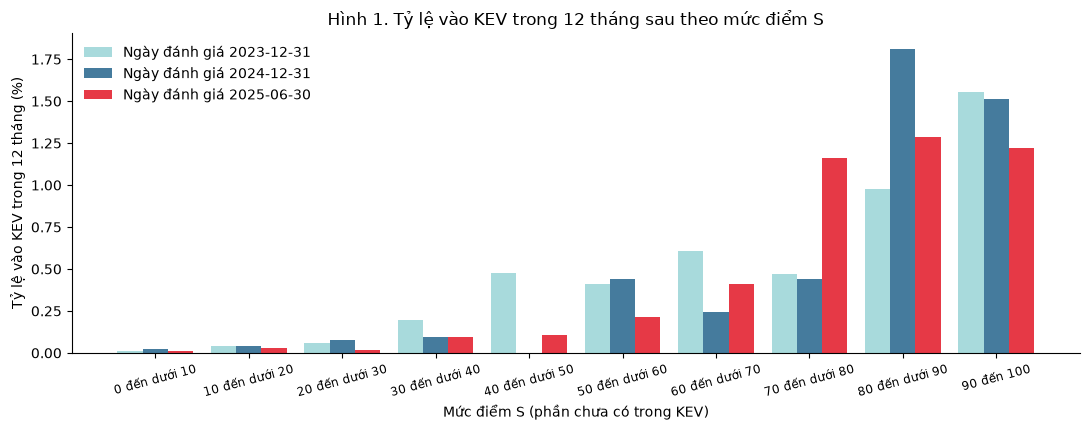

In [8]:
fig, ax = plt.subplots(figsize=(11, 4.4)); xx = np.arange(len(NHAN)); w = 0.27
for i, (T, m) in enumerate(zip(NGAY_DANH_GIA, ["#a8dadc", "#457b9d", "#e63946"])):
    r = [100 * SO_LIEU[T]["muc"][n]["k"] / SO_LIEU[T]["muc"][n]["n"] for n in NHAN]
    ax.bar(xx + (i - 1) * w, r, w, color=m, label=f"Ngày đánh giá {T}")
ax.set_xticks(xx); ax.set_xticklabels(NHAN, fontsize=8.5, rotation=15)
ax.set_ylabel("Tỷ lệ vào KEV trong 12 tháng (%)"); ax.set_xlabel("Mức điểm S (phần chưa có trong KEV)")
ax.legend(frameon=False); ax.set_title("Hình 1. Tỷ lệ vào KEV trong 12 tháng sau theo mức điểm S")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh1_ty_le_theo_muc.png"), dpi=170); plt.show()

## 9. Hình 2. Đường bắt được: vá càng nhiều thì bắt được bao nhiêu lỗ hổng sẽ vào KEV

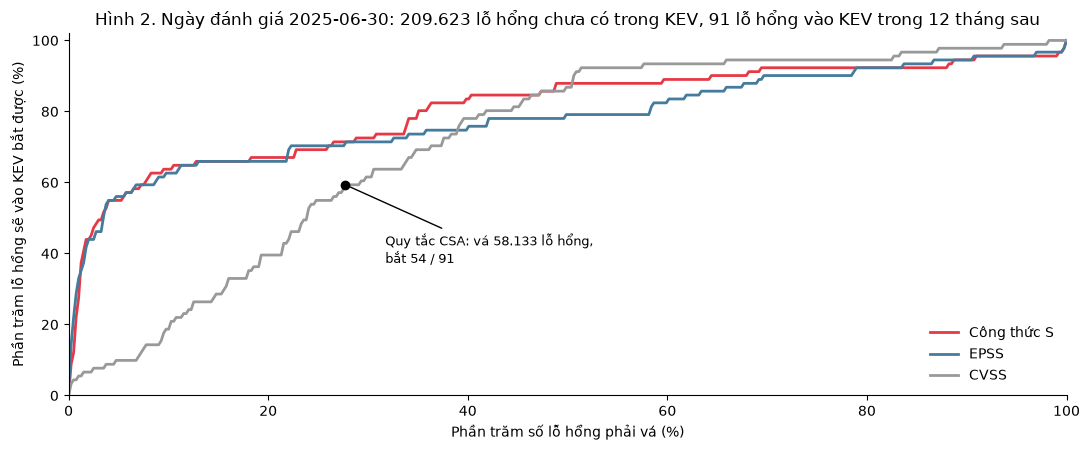

In [9]:
c = DL[NGAY_CHINH][DL[NGAY_CHINH]["kev"] == 0]; N, P = len(c), int(c["y"].sum())
ks = np.unique(np.linspace(1, N, 400).astype(int))
fig, ax = plt.subplots(figsize=(11, 4.6))
for m, ten, mau in [("S", "Công thức S", "#e63946"), ("epss", "EPSS", "#457b9d"), ("cvss", "CVSS", "#999999")]:
    v = c[m].values; o = np.lexsort((rng.random(N), -v)); cum = np.cumsum(c["y"].values[o])
    ax.plot(100 * ks / N, 100 * cum[ks - 1] / P, color=mau, lw=2, label=ten)
n_csa = SO_LIEU[NGAY_CHINH]["csa"]["n"]; k_csa = SO_LIEU[NGAY_CHINH]["csa"]["k"]
ax.scatter([100 * n_csa / N], [100 * k_csa / P], color="black", zorder=5)
ax.annotate(f"Quy tắc CSA: vá {so(n_csa)} lỗ hổng,\nbắt {k_csa} / {P}", (100 * n_csa / N, 100 * k_csa / P),
            xytext=(100 * n_csa / N + 4, 100 * k_csa / P - 22), arrowprops=dict(arrowstyle="-", color="black"), fontsize=9)
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_xlabel("Phần trăm số lỗ hổng phải vá (%)"); ax.set_ylabel("Phần trăm lỗ hổng sẽ vào KEV bắt được (%)")
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"Hình 2. Ngày đánh giá {NGAY_CHINH}: {so(N)} lỗ hổng chưa có trong KEV, {P} lỗ hổng vào KEV trong 12 tháng sau")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh2_duong_bat_duoc.png"), dpi=170); plt.show()

## 10. Lưu kết quả

In [10]:
with pd.ExcelWriter(os.path.join(OUT_DIR, "bang_kiem_chung_S.xlsx")) as w:
    for ten, b in BANG.items():
        b.to_excel(w, sheet_name=ten[:31], index=False)
for ten, b in BANG.items():
    b.to_csv(os.path.join(OUT_DIR, ten.replace(" ", "_") + ".csv"), index=False, encoding="utf-8-sig")
json.dump(SO_LIEU, open(os.path.join(OUT_DIR, "so_lieu_S.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2,
          default=lambda o: int(o) if isinstance(o, np.integer) else float(o))
print("Đã lưu:", ", ".join(sorted(os.listdir(OUT_DIR))))

Đã lưu: B1_Tong_quan.csv, B2_Muc_diem_2023-12-31.csv, B2_Muc_diem_2024-12-31.csv, B2_Muc_diem_2025-06-30.csv, B3_Tich_luy_2023-12-31.csv, B3_Tich_luy_2024-12-31.csv, B3_Tich_luy_2025-06-30.csv, B4_So_sanh_cung_khoi_luong.csv, B5_Phan_KEV.csv, bang_kiem_chung_S.xlsx, hinh1_ty_le_theo_muc.png, hinh2_duong_bat_duoc.png, so_lieu_S.json
